# Used Car Price Analysis in Pakistan

**DSTT Term Project – Part 1: Data Preprocessing and Exploratory Data Analysis**

**Team Members:**
- Amna Mushtaq (26L-8021)
- Ayman Saleem (26L-8028)
- Mehak Asim (26-8013)

## Project Overview

This project aims to analyze used-car prices in Pakistan using a historical dataset.

The target variable is the advertised car price in Pakistani Rupees (PKR).

In Part 1, we focus on:
- Dataset loading and understanding.
- Data cleaning and handling missing values.
- Feature engineering and selection.
- Data preprocessing.
- Exploratory Data Analysis (EDA).
- Identifying important observations and insights.

The next phase will focus on building and evaluating machine learning models for used-car price prediction.

## 1. Dataset Source and Setup

**Dataset:** Pakistan Used Car Prices 2023, Talha Barkaat Ahmad, Kaggle.

**Source:** https://www.kaggle.com/datasets/talhabarkaatahmad/pakistan-used-car-prices-2023

Upload **pakwheels_used_car_data_v02.csv** using the button below. Run the first code cell, complete the upload and then run the next cell.

In [1]:
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import ipywidgets as widgets

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

upload = widgets.FileUpload(
    accept=".csv",
    multiple=False,
    description="Upload CSV"
)

display(upload)

FileUpload(value={}, accept='.csv', description='Upload CSV')

In [2]:
uploaded_file = (
    next(iter(upload.value.values()))
    if isinstance(upload.value, dict)
    else upload.value[0]
)

raw_data = pd.read_csv(BytesIO(bytes(uploaded_file["content"])))

display(raw_data.head())

,addref,city,assembly,body,make,model,year,engine,transmission,fuel,color,registered,mileage,price
0,7943732,Peshawar,NaN,Sedan,Toyota,Corolla,2013.0,1300.0,Manual,Petrol,Silver Metallic,Lahore,145000,2870000.0
1,7730314,Lahore,NaN,Sedan,Honda,City,2000.0,1300.0,Manual,Petrol,Blue,Lahore,230000,995000.0
2,7943737,Lahore,NaN,Sedan,Toyota,Yaris,2021.0,1300.0,Manual,Petrol,Super White,Punjab,60500,3585000.0
3,7943733,Lahore,NaN,Hatchback,Suzuki,Swift,2017.0,1300.0,Manual,Petrol,Grey,Islamabad,87000,2250000.0
4,7923484,Lahore,NaN,Sedan,Honda,Civic,2017.0,1800.0,Automatic,Petrol,Grey,Lahore,86000,4850000.0


## 2. Dataset Description

We explore the original dataset to understand its structure and quality.

We examine:
- Total number of rows and columns.
- Data types of each column.
- Number and percentage of missing values.
- Number of unique values in each column.
- Number of unique advertisement IDs.

This helps us identify data quality issues before cleaning and preprocessing.

In [3]:
dataset_summary = pd.DataFrame({
    "dtype": raw_data.dtypes.astype(str),
    "missing": raw_data.isna().sum(),
    "missing_pct": (raw_data.isna().mean() * 100).round(2),
    "unique_values": raw_data.nunique(dropna=True),
})

display(pd.DataFrame({"rows": [len(raw_data)], "columns": [raw_data.shape[1]], "unique_ads": [raw_data["addref"].nunique()]}))
display(dataset_summary)


,rows,columns,unique_ads
0,77878,14,77878


,dtype,missing,missing_pct,unique_values
addref,int64,0,0.00,77878
city,object,0,0.00,297
assembly,object,53689,68.94,1
body,object,8904,11.43,21
make,object,0,0.00,68
model,object,0,0.00,435
year,float64,4779,6.14,33
engine,float64,3,0.00,229
transmission,object,0,0.00,2
fuel,object,906,1.16,3


### 2.1 Feature meanings

| Column | Description |
| --- | --- |
| `addref` | Advertisement reference; used for identification, not prediction |
| `city`, `registered` | Advertisement city and registration location |
| `make`, `model`, `body` | Vehicle manufacturer, model and body type |
| `year`, `engine`, `mileage` | Manufacturing year, engine capacity (cc), distance driven (km) |
| `assembly`, `transmission`, `fuel`, `color` | Vehicle specifications |
| `price` | Advertised asking price in PKR (target) |

An advertisement reference is not a meaningful price predictor. It will be excluded from the feature matrix.


## 3. Data Cleaning

We clean the dataset to improve data quality before analysis.

The cleaning process includes:
- Handling missing and invalid values.
- Removing records with missing or nonpositive prices.
- Checking duplicate advertisements.
- Identifying invalid manufacturing years, engine capacities, and mileage.
- Detecting potential outliers in prices and mileage.

Extreme values are flagged for further inspection rather than automatically removed, as some may represent genuine vehicle listings.

In [4]:
data = raw_data.copy()
data.columns = data.columns.str.strip().str.lower()

text_columns = ["city", "assembly", "body", "make", "model", "transmission", "fuel", "color", "registered"]

for column in text_columns:
    data[column] = data[column].astype("string").str.strip()
    data[column] = data[column].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

numeric_columns = ["year", "engine", "mileage", "price"]

for column in numeric_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

initial_rows = len(data)
duplicate_ids = int(data["addref"].duplicated().sum())
duplicate_records = int(data.drop(columns="addref").duplicated().sum())

data = data.drop_duplicates(subset="addref", keep="first")
data = data.loc[data["price"].notna() & (data["price"] > 0)].copy()
data.loc[~data["year"].between(1990, 2023), "year"] = np.nan
data.loc[~data["engine"].between(500, 7000), "engine"] = np.nan
data.loc[~data["mileage"].between(1, 1000000), "mileage"] = np.nan

data["price_outlier_flag"] = data["price"] > 100_000_000
data["mileage_placeholder_flag"] = data["mileage"].eq(1)

cleaning_summary = pd.DataFrame({
    "check": ["Raw records", "Duplicate advertisement IDs", "Repeated feature rows", "Rows after valid-price filtering", "High-price flags", "Mileage = 1 flags"],
    "count": [initial_rows, duplicate_ids, duplicate_records, len(data), int(data["price_outlier_flag"].sum()), int(data["mileage_placeholder_flag"].sum())],
})

display(cleaning_summary)
display(data.isna().sum().sort_values(ascending=False).to_frame("missing_after_cleaning"))


,check,count
0,Raw records,77878
1,Duplicate advertisement IDs,0
2,Repeated feature rows,388
3,Rows after valid-price filtering,77295
4,High-price flags,23
5,Mileage = 1 flags,867


,missing_after_cleaning
assembly,53398
body,8857
year,4623
color,1426
fuel,894
engine,202
addref,0
city,0
make,0
model,0


### 3.1 Missing-Value Handling

We handle missing values using the following methods:

- **Price:** Remove rows with missing prices because price is our target variable.
- **Numerical features:** Fill missing values using the median calculated from the training data.
- **Categorical features:** Replace missing values with `Unknown`.
- **Assembly:** Exclude this feature because approximately 69% of its values are missing.
- **Duplicate records:** Remove duplicate advertisement IDs. Keep other similar records because they may represent different cars.

These steps help us retain useful data while reducing data loss and preventing data leakage.

## 4. Feature Engineering and Selection

We create new features to better understand the factors affecting used-car prices.

- **Vehicle Age:** Calculated by subtracting the manufacturing year from 2023.
- **Mileage per Year:** Calculated by dividing total mileage by vehicle age.
- **Engine Band:** Groups cars into categories based on engine capacity.

We use 2023 as the reference year because the dataset does not provide exact listing dates.

For feature selection, we keep useful vehicle details such as make, model, year, mileage, fuel type, and transmission.

We exclude advertisement IDs, assembly type (due to missing values), and outlier flags from the selected features.

In [5]:
reference_year = 2023

data["vehicle_age"] = reference_year - data["year"]
data["mileage_per_year"] = data["mileage"] / data["vehicle_age"].clip(lower=1)
data["engine_band"] = pd.cut(
    data["engine"],
    bins=[0, 1000, 1600, 2500, 7000],
    labels=["Small", "Medium", "Large", "Very Large"],
    include_lowest=True,
)

categorical_features = ["city", "body", "make", "model", "transmission", "fuel", "registered", "engine_band"]
numeric_features = ["year", "engine", "mileage", "vehicle_age", "mileage_per_year"]
selected_features = categorical_features + numeric_features

display(data[selected_features + ["price"]].head())
display(pd.DataFrame({"feature": selected_features, "type": ["categorical"] * len(categorical_features) + ["numeric"] * len(numeric_features)}))


,city,body,make,model,transmission,fuel,registered,engine_band,year,engine,mileage,vehicle_age,mileage_per_year,price
0,Peshawar,Sedan,Toyota,Corolla,Manual,Petrol,Lahore,Medium,2013.0,1300.0,145000.0,10.0,14500.000000,2870000.0
1,Lahore,Sedan,Honda,City,Manual,Petrol,Lahore,Medium,2000.0,1300.0,230000.0,23.0,10000.000000,995000.0
2,Lahore,Sedan,Toyota,Yaris,Manual,Petrol,Punjab,Medium,2021.0,1300.0,60500.0,2.0,30250.000000,3585000.0
3,Lahore,Hatchback,Suzuki,Swift,Manual,Petrol,Islamabad,Medium,2017.0,1300.0,87000.0,6.0,14500.000000,2250000.0
4,Lahore,Sedan,Honda,Civic,Automatic,Petrol,Lahore,Large,2017.0,1800.0,86000.0,6.0,14333.333333,4850000.0


,feature,type
0,city,categorical
1,body,categorical
2,make,categorical
3,model,categorical
4,transmission,categorical
5,fuel,categorical
6,registered,categorical
7,engine_band,categorical
8,year,numeric
9,engine,numeric


## 5. Preprocessing Pipeline

We prepare the data for machine learning by applying the following preprocessing steps:

- **Train-Test Split:** Divide the dataset into 80% training data and 20% testing data.
- **Missing Numerical Values:** Fill missing values using the training data median.
- **Missing Categorical Values:** Replace missing values with `Unknown`.
- **Standard Scaling:** Scale numerical features to a common range of values.
- **One-Hot Encoding:** Convert categorical features into numerical form.

We use a preprocessing pipeline to apply these steps consistently.

All preprocessing methods are fitted on the training data only to prevent data leakage. Model training and evaluation will be performed in Part 2.

In [6]:
X = data[selected_features].copy()
X[categorical_features] = X[categorical_features].astype(object).where(X[categorical_features].notna(), np.nan)
y = data["price"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

display(pd.DataFrame({
    "split": ["Training", "Testing"],
    "rows": [X_train_transformed.shape[0], X_test_transformed.shape[0]],
    "transformed_features": [X_train_transformed.shape[1], X_test_transformed.shape[1]],
}))


,split,rows,transformed_features
0,Training,61836,921
1,Testing,15459,921


## 6. Exploratory Data Analysis (EDA)

We use different graphs to understand the dataset and identify patterns in used-car prices.

The visualizations help us analyze:

- Distribution of car prices and mileage.
- Most common car makes and manufacturing years.
- Price differences between car manufacturers.
- Relationship between mileage and asking price.
- Correlation between numerical features.
- Cities with the most car listings.
- Missing values in selected features.

For better visualization, some graphs exclude extreme values so that common patterns are easier to understand.

These graphs show relationships and trends but do not prove that one feature directly causes a change in price.

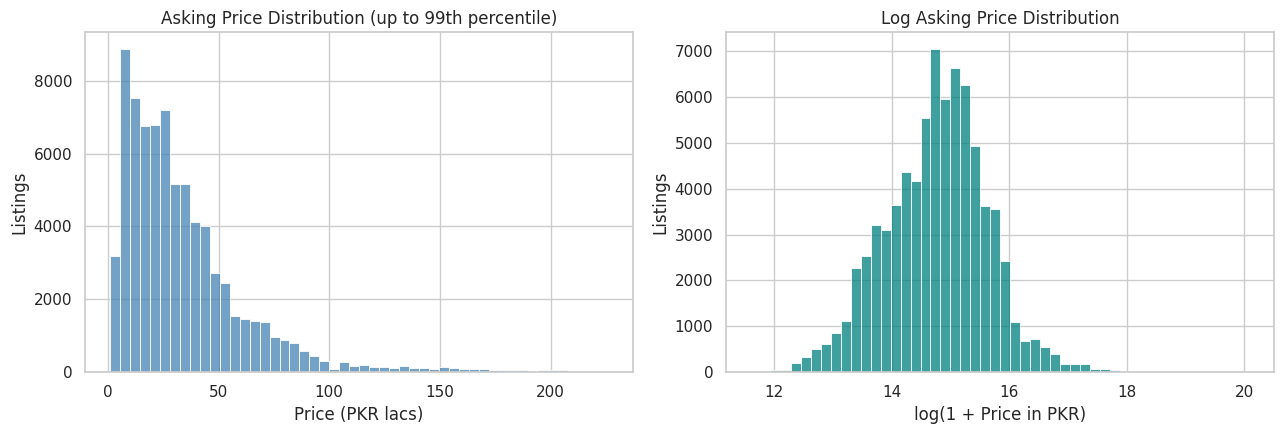

In [7]:
price_lacs = data["price"] / 100_000

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(price_lacs[price_lacs <= price_lacs.quantile(0.99)], bins=50, ax=axes[0], color="steelblue")
axes[0].set(title="Asking Price Distribution (up to 99th percentile)", xlabel="Price (PKR lacs)", ylabel="Listings")
sns.histplot(np.log1p(data["price"]), bins=50, ax=axes[1], color="teal")
axes[1].set(title="Log Asking Price Distribution", xlabel="log(1 + Price in PKR)", ylabel="Listings")
plt.tight_layout()
plt.show()


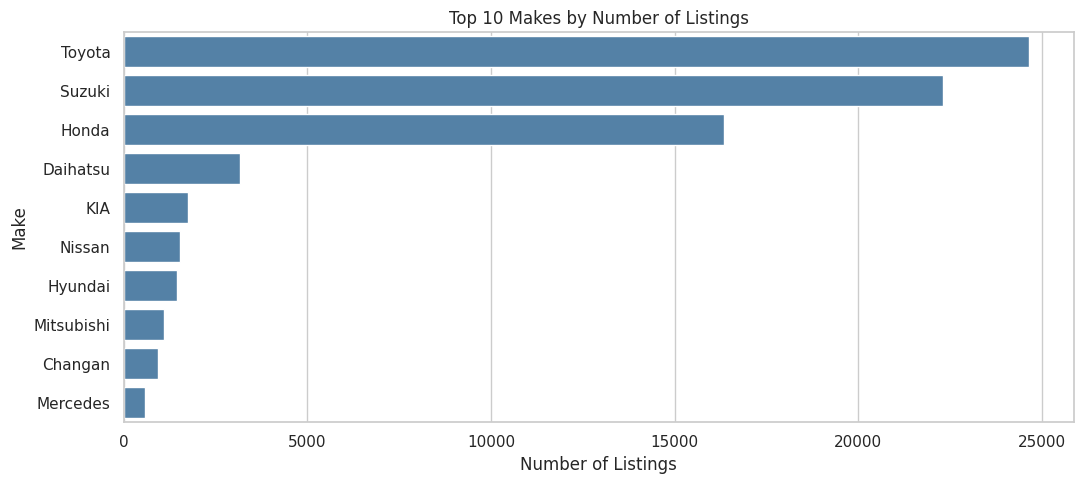

In [8]:
top_makes = data["make"].value_counts().head(10)

plt.figure(figsize=(11, 5))
sns.barplot(x=top_makes.values, y=top_makes.index, color="steelblue")
plt.title("Top 10 Makes by Number of Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Make")
plt.tight_layout()
plt.show()


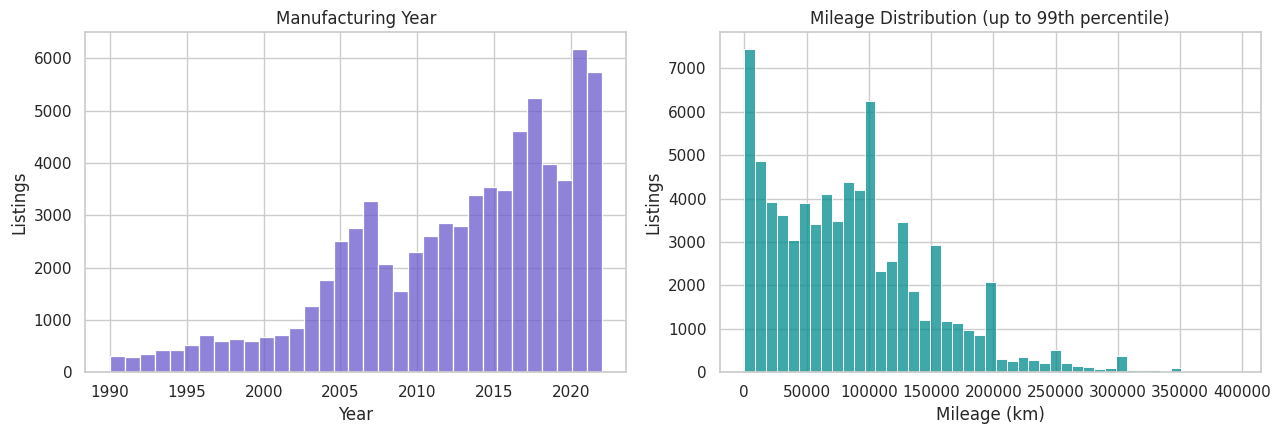

In [9]:
valid_years = data.loc[data["year"].between(1990, 2023)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(valid_years["year"], bins=33, ax=axes[0], color="slateblue")
axes[0].set(title="Manufacturing Year", xlabel="Year", ylabel="Listings")
sns.histplot(data.loc[data["mileage"] <= data["mileage"].quantile(0.99), "mileage"], bins=45, ax=axes[1], color="darkcyan")
axes[1].set(title="Mileage Distribution (up to 99th percentile)", xlabel="Mileage (km)", ylabel="Listings")
plt.tight_layout()
plt.show()


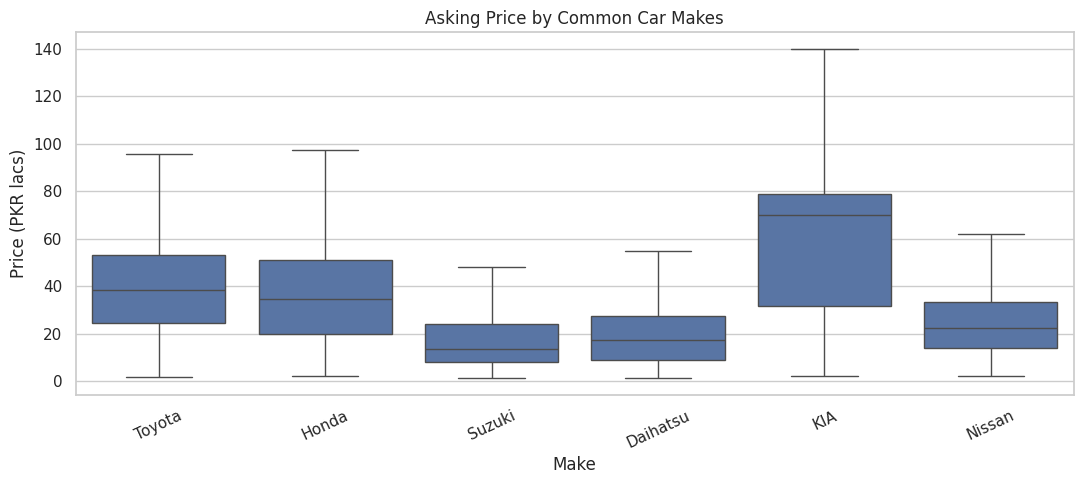

In [10]:
common_makes = data["make"].value_counts().head(6).index
make_prices = data.loc[data["make"].isin(common_makes) & (data["price"] <= data["price"].quantile(0.99))].copy()
make_prices["price_lacs"] = make_prices["price"] / 100_000

plt.figure(figsize=(11, 5))
sns.boxplot(data=make_prices, x="make", y="price_lacs", showfliers=False)
plt.title("Asking Price by Common Car Makes")
plt.xlabel("Make")
plt.ylabel("Price (PKR lacs)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


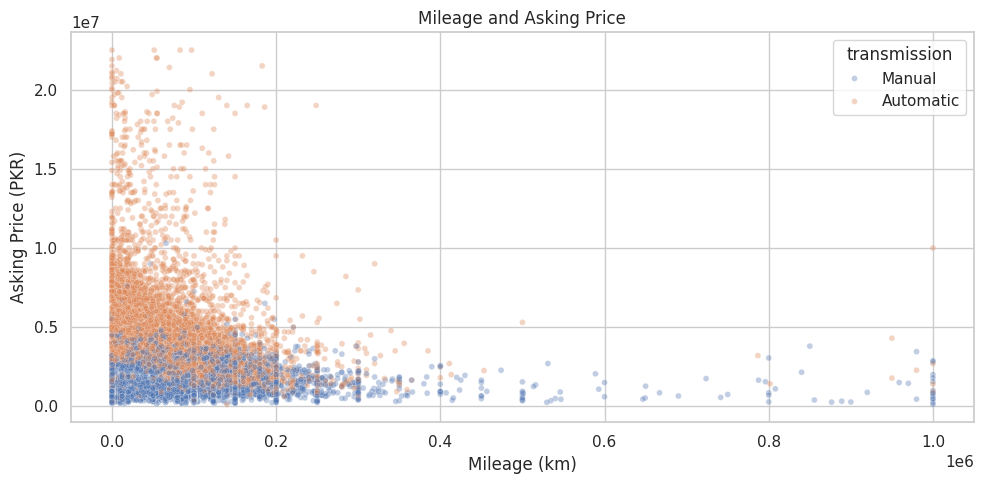

In [11]:
sample_size = min(10000, len(data))
eda_sample = data.sample(n=sample_size, random_state=42)
eda_sample = eda_sample.loc[eda_sample["price"] <= data["price"].quantile(0.99)]

plt.figure(figsize=(10, 5))
sns.scatterplot(data=eda_sample, x="mileage", y="price", hue="transmission", alpha=0.35, s=18)
plt.title("Mileage and Asking Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Asking Price (PKR)")
plt.tight_layout()
plt.show()


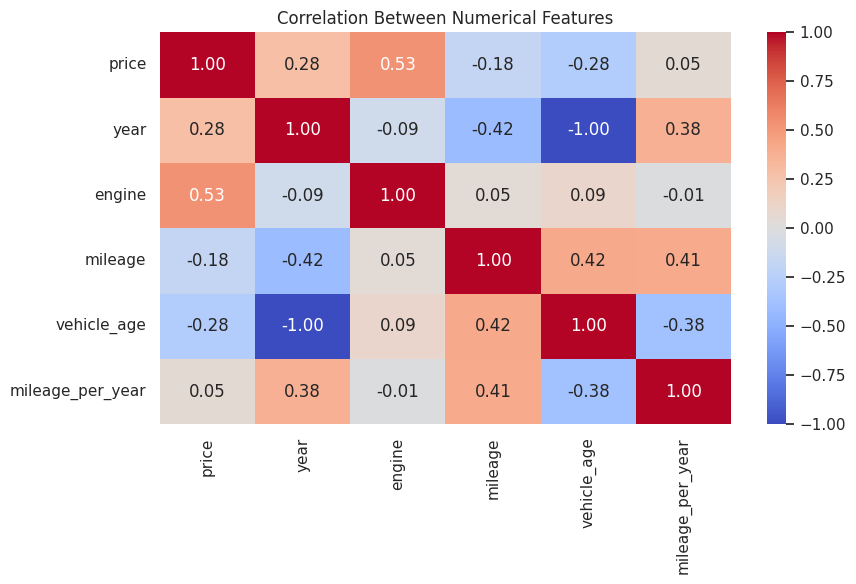

In [12]:
numeric_eda = data[["price", "year", "engine", "mileage", "vehicle_age", "mileage_per_year"]]

plt.figure(figsize=(9, 6))
sns.heatmap(numeric_eda.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


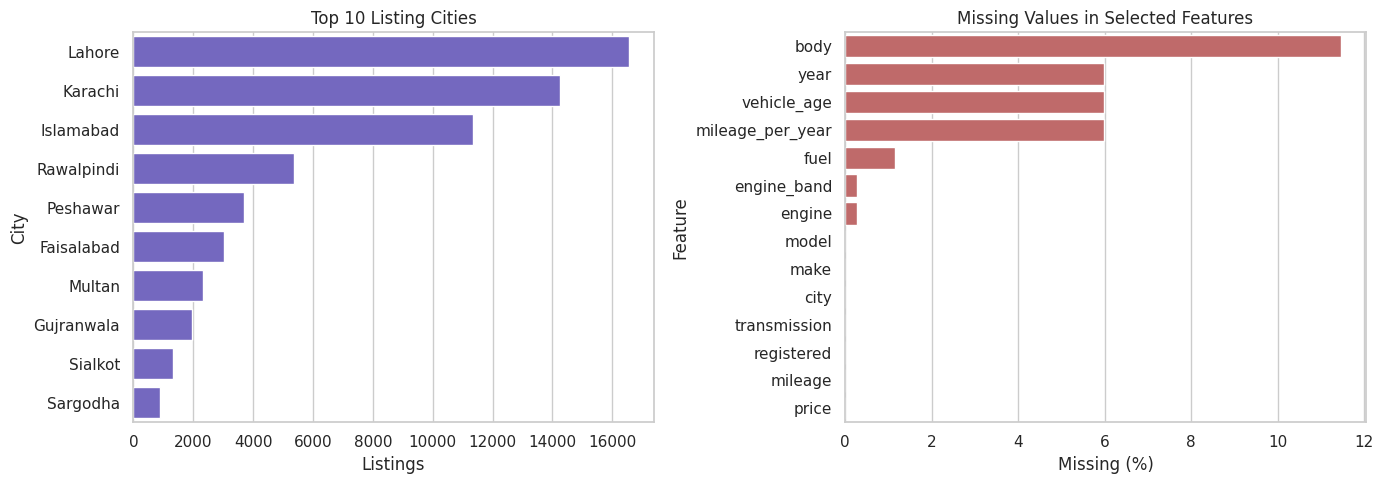

In [13]:
top_cities = data["city"].value_counts().head(10)
missing_pct = data[selected_features + ["price"]].isna().mean().mul(100).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=top_cities.values, y=top_cities.index, ax=axes[0], color="slateblue")
axes[0].set(title="Top 10 Listing Cities", xlabel="Listings", ylabel="City")
sns.barplot(x=missing_pct.values, y=missing_pct.index, ax=axes[1], color="indianred")
axes[1].set(title="Missing Values in Selected Features", xlabel="Missing (%)", ylabel="Feature")
plt.tight_layout()
plt.show()


## 7. Key Observations and Insights

We analyze the cleaned dataset to identify important findings, including:

- Total number of usable car listings.
- Median and 75th percentile of advertised car prices.
- Most common car manufacturer.
- Percentage of missing assembly information.
- Number of listings with unusually high prices.
- Number of listings with suspicious mileage values.

These observations help us understand the dataset and identify potential data quality issues.

In [14]:
price_summary = data["price"].quantile([0.25, 0.5, 0.75, 0.95]).round(0)
top_make = data["make"].value_counts().idxmax()
missing_assembly_pct = raw_data["assembly"].isna().mean() * 100

insights = pd.DataFrame({
    "Observation": [
        "Usable records with asking price",
        "Median advertised price (PKR)",
        "75th percentile asking price (PKR)",
        "Most common make",
        "Missing assembly information (%)",
        "Records with suspiciously high prices (> PKR 100m)",
        "Records with mileage equal to 1 km",
    ],
    "Value": [
        f"{len(data):,}",
        f"{price_summary.loc[0.5]:,.0f}",
        f"{price_summary.loc[0.75]:,.0f}",
        top_make,
        f"{missing_assembly_pct:.1f}",
        f"{data['price_outlier_flag'].sum():,}",
        f"{data['mileage_placeholder_flag'].sum():,}",
    ],
})

display(insights)


,Observation,Value
0,Usable records with asking price,"77,295"
1,Median advertised price (PKR),"2,700,000"
2,75th percentile asking price (PKR),"4,500,000"
3,Most common make,Toyota
4,Missing assembly information (%),68.9
5,Records with suspiciously high prices (> PKR 1...,23
6,Records with mileage equal to 1 km,867


## 8. Part 1 Summary

In this phase, we completed the following tasks:

- Loaded and explored the used-car dataset.
- Cleaned the data and handled missing values.
- Identified duplicates and potential outliers.
- Created and selected useful features.
- Prepared the data using a preprocessing pipeline.
- Performed EDA using different visualizations.
- Identified important patterns and relationships in the dataset.




---

# Part 2: Model Training, Evaluation and Complete Pipeline

The preceding Part 1 is preserved without changes. The following cells continue the same project using the cleaned data and engineered features. For final model evaluation, the Part 1 exploratory 80/20 split is replaced with a separate training, validation and testing split. High-price observations flagged in Part 1 are excluded from the model training scope, but remain in the original Part 1 analysis.


In [15]:
from joblib import dump
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder

model_data = data.loc[~data["price_outlier_flag"]].copy()
data = model_data

X = data[selected_features].copy()
X[categorical_features] = X[categorical_features].astype(object).where(X[categorical_features].notna(), np.nan)
y = data["price"].copy()

display(pd.DataFrame({
    "Part 1 usable rows": [len(model_data) + int(cleaning_summary.loc[cleaning_summary["check"] == "High-price flags", "count"].iloc[0])],
    "Modeling rows": [len(model_data)],
    "Excluded high-price rows": [int(cleaning_summary.loc[cleaning_summary["check"] == "High-price flags", "count"].iloc[0])],
}))


,Part 1 usable rows,Modeling rows,Excluded high-price rows
0,77295,77272,23


## 3. Training, Validation and Testing Sets

We use approximately 70% training, 15% validation and 15% testing. The training set fits models, the validation set compares them, and the test set provides one final evaluation after selection.

Listings sharing the same make, model, manufacturing year, mileage and city form one group. We keep these groups in only one split to reduce duplicate-listing leakage. This grouping is approximate because the dataset has no stable vehicle ID.

In [16]:
groups = data[["make", "model", "year", "mileage", "city"]].astype("string").fillna("Unknown").agg("|".join, axis=1)

initial_split = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, remaining_idx = next(initial_split.split(X, y, groups))

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_remaining, y_remaining = X.iloc[remaining_idx], y.iloc[remaining_idx]
groups_train = groups.iloc[train_idx]
groups_remaining = groups.iloc[remaining_idx]

final_split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
validation_idx, test_idx = next(final_split.split(X_remaining, y_remaining, groups_remaining))

X_val, y_val = X_remaining.iloc[validation_idx], y_remaining.iloc[validation_idx]
X_test, y_test = X_remaining.iloc[test_idx], y_remaining.iloc[test_idx]

groups_val = groups_remaining.iloc[validation_idx]
groups_test = groups_remaining.iloc[test_idx]

assert not (set(groups_train) & set(groups_val))
assert not (set(groups_train) & set(groups_test))
assert not (set(groups_val) & set(groups_test))

split_summary = pd.DataFrame({
    "split": ["Training", "Validation", "Testing"],
    "rows": [len(X_train), len(X_val), len(X_test)],
    "percentage": [100 * len(X_train) / len(X), 100 * len(X_val) / len(X), 100 * len(X_test) / len(X)],
})
display(split_summary.round(2))

,split,rows,percentage
0,Training,54041,69.94
1,Validation,11625,15.04
2,Testing,11606,15.02


## 4. Model Selection

We test five approaches:

1. **Dummy Regressor:** Predicts a constant value and establishes a baseline.
2. **Ridge Regression:** A regularized linear model using one-hot encoded vehicle details.
3. **Log-Price Ridge Regression:** Uses the same model but fits the logarithm of prices and converts predictions back to PKR.
4. **Random Forest:** Learns nonlinear relationships from the encoded vehicle details.
5. **Histogram Gradient Boosting:** A tree-based boosting model. It uses grouped category codes and handles categorical variables explicitly.

Each model includes preprocessing inside its pipeline. This prevents missing-value treatment or encoding from being fitted on validation or test data.

In [17]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

linear_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

boosting_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("encoder", OrdinalEncoder(max_categories=80, handle_unknown="use_encoded_value", unknown_value=-1)),
    ]), categorical_features),
])

models = {
    "Baseline": Pipeline([
        ("preprocessor", linear_preprocessor),
        ("model", DummyRegressor(strategy="median")),
    ]),
    "Ridge": Pipeline([
        ("preprocessor", linear_preprocessor),
        ("model", Ridge(alpha=10.0)),
    ]),
    "Log Ridge": Pipeline([
        ("preprocessor", linear_preprocessor),
        ("model", TransformedTargetRegressor(regressor=Ridge(alpha=10.0), func=np.log1p, inverse_func=np.expm1)),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", linear_preprocessor),
        ("model", RandomForestRegressor(n_estimators=80, max_depth=22, min_samples_leaf=3, n_jobs=-1, random_state=42)),
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", boosting_preprocessor),
        ("model", HistGradientBoostingRegressor(
            max_iter=160,
            max_leaf_nodes=31,
            learning_rate=0.08,
            categorical_features=[False] * len(numeric_features) + [True] * len(categorical_features),
            random_state=42,
        )),
    ]),
}

## 5. Model Training and Validation

We compare models using three metrics. **MAE** is the average absolute error in PKR. **RMSE** penalizes large errors more heavily. **R²** measures how much price variation is explained by the model.

For MAE and RMSE, lower is better. For R², higher is better. The test set is not used at this stage.

In [18]:
def calculate_metrics(actual, predicted):
    return {
        "MAE (PKR)": mean_absolute_error(actual, predicted),
        "RMSE (PKR)": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }

validation_results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = np.maximum(model.predict(X_val), 0)
    validation_results.append({"Model": name, **calculate_metrics(y_val, predictions)})
    fitted_models[name] = model

comparison = pd.DataFrame(validation_results).sort_values("MAE (PKR)").reset_index(drop=True)
display(comparison.round({"MAE (PKR)": 0, "RMSE (PKR)": 0, "R2": 3}))

,Model,MAE (PKR),RMSE (PKR),R2
0,Random Forest,367253.0,1472359.0,0.920
1,Gradient Boosting,411259.0,1399856.0,0.928
2,Log Ridge,752179.0,2773600.0,0.717
3,Ridge,1135319.0,3170314.0,0.630
4,Baseline,2368011.0,5331646.0,-0.047


## 6. Hyperparameter Tuning

We tune the gradient-boosting model using `RandomizedSearchCV` and grouped cross-validation on the training set. This tests different tree sizes, learning rates and training iterations without using the validation or test labels for fitting.

The search is deliberately small so the notebook remains practical to execute on an ordinary laptop.

In [33]:
parameter_options = {
    "model__learning_rate": [0.05, 0.08, 0.12],
    "model__max_leaf_nodes": [15, 31, 45],
    "model__max_iter": [120, 180, 240],
    "model__min_samples_leaf": [20, 40],
}

search = RandomizedSearchCV(
    estimator=models["Gradient Boosting"],
    param_distributions=parameter_options,
    n_iter=5,
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=3),
    random_state=42,
    n_jobs=-1,
    refit=True,
)

search.fit(X_train, y_train, groups=groups_train)
tuned_model = search.best_estimator_
tuned_predictions = np.maximum(tuned_model.predict(X_val), 0)

comparison = pd.concat([
    comparison,
    pd.DataFrame([{"Model": "Tuned Gradient Boosting", **calculate_metrics(y_val, tuned_predictions)}]),
], ignore_index=True).sort_values("MAE (PKR)").reset_index(drop=True)

display(pd.DataFrame([search.best_params_]))
print("\n")
display(comparison.round({"MAE (PKR)": 0, "RMSE (PKR)": 0, "R2": 3}))

,model__min_samples_leaf,model__max_leaf_nodes,model__max_iter,model__learning_rate
0,20,31,180,0.12


,Model,MAE (PKR),RMSE (PKR),R2
0,Random Forest,367253.0,1472359.0,0.920
1,Tuned Gradient Boosting,407397.0,1376574.0,0.930
2,Tuned Gradient Boosting,407397.0,1376574.0,0.930
3,Gradient Boosting,411259.0,1399856.0,0.928
4,Log Ridge,752179.0,2773600.0,0.717
5,Ridge,1135319.0,3170314.0,0.630
6,Baseline,2368011.0,5331646.0,-0.047


## 7. Model Comparison and Visualization

We compare MAE, RMSE and R² on the validation set. The evaluation charts allow us to see differences that are difficult to judge from a table alone.

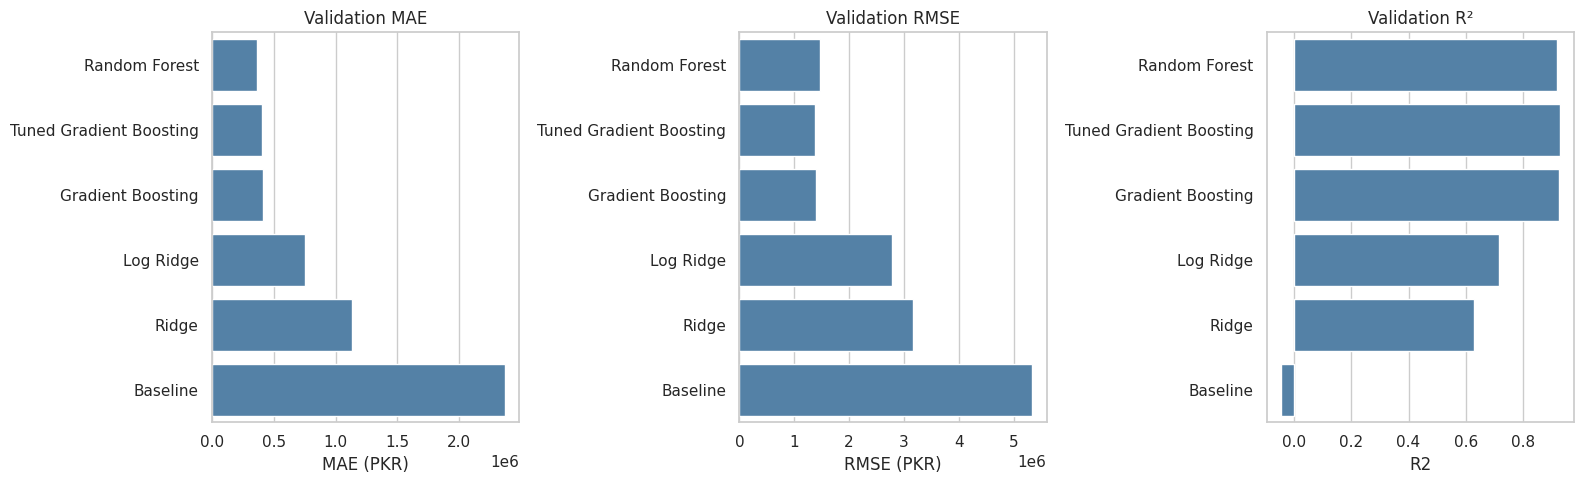

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for axis, metric, title in zip(
    axes,
    ["MAE (PKR)", "RMSE (PKR)", "R2"],
    ["Validation MAE", "Validation RMSE", "Validation R²"],
):
    sns.barplot(data=comparison, x=metric, y="Model", ax=axis, color="steelblue")
    axis.set_title(title)
    axis.set_ylabel("")
plt.tight_layout()
plt.show()

## 8. Final Model Selection

We select the model with the lowest validation MAE. The winning model is refitted on the combined training and validation sets. Only after this decision do we evaluate it on the untouched test set.

**Random Forest Regressor** was selected as the final model because it achieved the lowest Mean Absolute Error (MAE) on the validation dataset. Although Tuned Gradient Boosting achieved a slightly higher R² score, Random Forest produced lower average prediction errors in PKR, which was our primary evaluation criterion.

After selection, Random Forest was retrained using the combined training and validation datasets and evaluated on the previously unseen test dataset.

Fi

In [21]:
from sklearn.base import clone

model_candidates = {**fitted_models, "Tuned Gradient Boosting": tuned_model}
best_name = comparison.iloc[0]["Model"]
final_pipeline = clone(model_candidates[best_name])

X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = pd.concat([y_train, y_val], axis=0)
final_pipeline.fit(X_train_final, y_train_final)

test_predictions = np.maximum(final_pipeline.predict(X_test), 0)
test_results = pd.DataFrame([{"Selected Model": best_name, **calculate_metrics(y_test, test_predictions)}])

display(test_results.round({"MAE (PKR)": 0, "RMSE (PKR)": 0, "R2": 3}))

,Selected Model,MAE (PKR),RMSE (PKR),R2
0,Random Forest,377481.0,1424968.0,0.927


## 9. Test Performance and Error Analysis

The plots below show predicted versus actual prices, the distribution of residuals and the error across price ranges. Residuals are calculated as actual price minus predicted price. We also report MAE for common makes to check whether the model performs equally well for different vehicle groups.

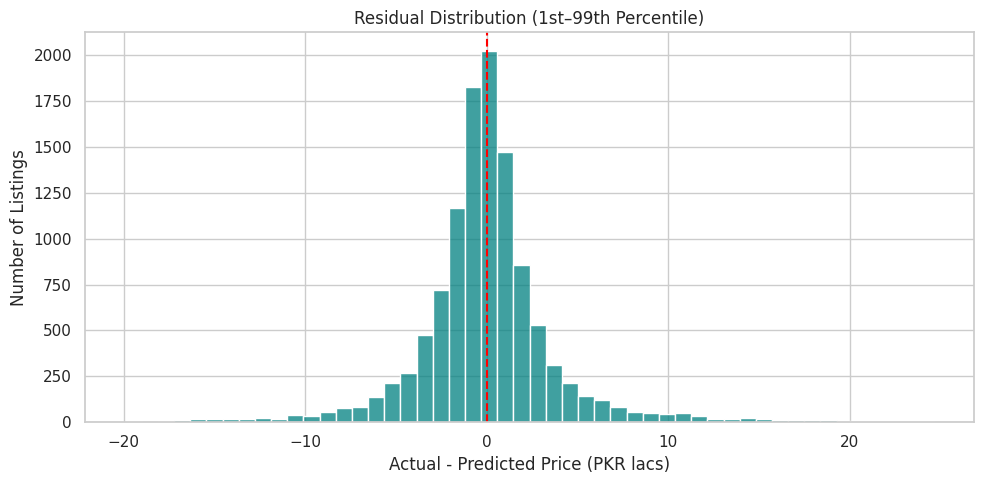

In [26]:
residuals = y_test.to_numpy() - test_predictions

lower = np.percentile(residuals, 1)
upper = np.percentile(residuals, 99)

filtered_residuals = residuals[
    (residuals >= lower) & (residuals <= upper)
]

plt.figure(figsize=(10, 5))
sns.histplot(filtered_residuals / 100_000, bins=50, color="teal")

plt.axvline(0, color="red", linestyle="--")
plt.title("Residual Distribution (1st–99th Percentile)")
plt.xlabel("Actual - Predicted Price (PKR lacs)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

,Price Range,MAE (PKR),Listings
0,Below 10 lac,148484.0,1794
1,10-30 lac,202600.0,4623
2,30-50 lac,320356.0,2772
3,50-100 lac,489516.0,1851
4,Above 100 lac,2445102.0,566


,Make,MAE (PKR),Listings
0,Suzuki,162088.0,3416
1,Daihatsu,180142.0,444
2,Honda,254909.0,2373
3,Nissan,357237.0,224
4,KIA,373272.0,295
5,Toyota,495230.0,3707


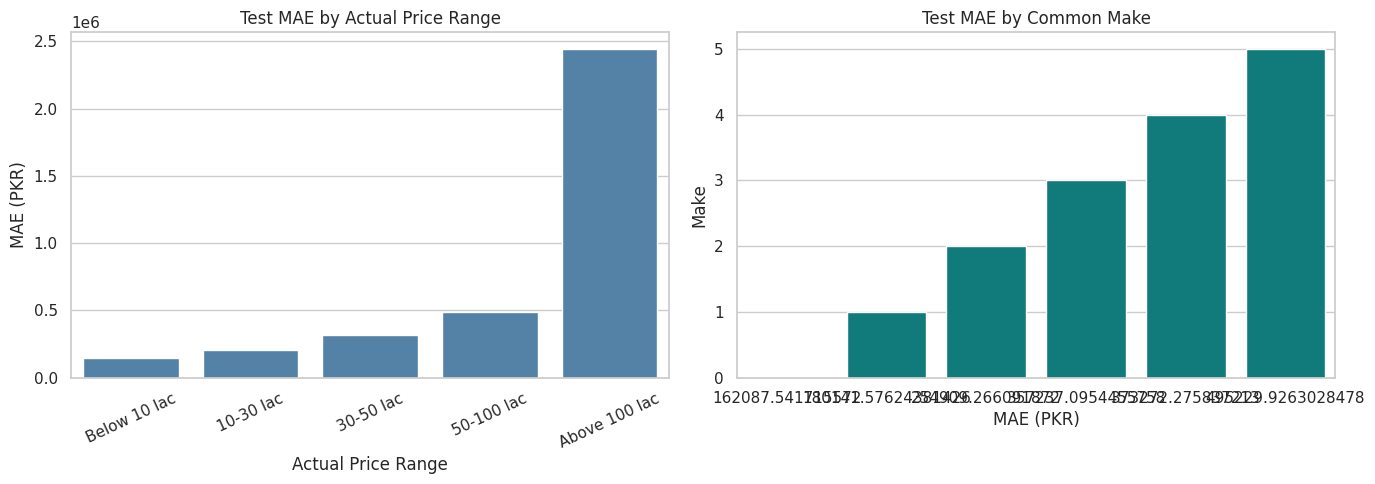

In [36]:
error_data = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": test_predictions,
    "make": X_test["make"].to_numpy(),
})
error_data["absolute_error"] = (error_data["actual"] - error_data["predicted"]).abs()
error_data["price_range"] = pd.cut(
    error_data["actual"],
    bins=[0, 1_000_000, 3_000_000, 5_000_000, 10_000_000, 100_000_000],
    labels=["Below 10 lac", "10-30 lac", "30-50 lac", "50-100 lac", "Above 100 lac"],
    include_lowest=True,
)

range_errors = error_data.groupby("price_range", observed=True)["absolute_error"].agg(["mean", "count"]).reset_index()
range_errors.columns = ["Price Range", "MAE (PKR)", "Listings"]

common_makes = error_data["make"].value_counts().head(6).index
make_errors = error_data[error_data["make"].isin(common_makes)].groupby("make")["absolute_error"].agg(["mean", "count"]).sort_values("mean").reset_index()

display(range_errors.round({"MAE (PKR)": 0}))
print("\n")
display(make_errors.rename(columns={"make": "Make", "mean": "MAE (PKR)", "count": "Listings"}).round(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=range_errors, x="Price Range", y="MAE (PKR)", ax=axes[0], color="steelblue")
axes[0].set(title="Test MAE by Actual Price Range", xlabel="Actual Price Range", ylabel="MAE (PKR)")
axes[0].tick_params(axis="x", rotation=25)
sns.barplot(x=make_errors["mean"].values, y=make_errors.index, ax=axes[1], color="darkcyan")
axes[1].set(title="Test MAE by Common Make", xlabel="MAE (PKR)", ylabel="Make")
plt.tight_layout()
plt.show()

## 10. Model Interpretation and Complete Pipeline

We use permutation importance on a sample of the final test inputs. This estimates how much test MAE changes when one feature is shuffled. It is model-independent and works for the full pipeline. Correlated features can share importance, so rankings should not be interpreted as causes.

We then save the final fitted preprocessing-and-model pipeline. Load it only from a trusted source because serialized model files can execute code during loading.

,Feature,Increase in MAE (PKR)
9,engine,1.707343e+06
8,year,5.846920e+05
11,vehicle_age,5.384801e+05
4,transmission,5.341382e+05
3,model,3.578646e+05
1,body,2.303201e+05
2,make,2.175178e+05
10,mileage,1.914777e+05
7,engine_band,1.095502e+05
5,fuel,9.978049e+04


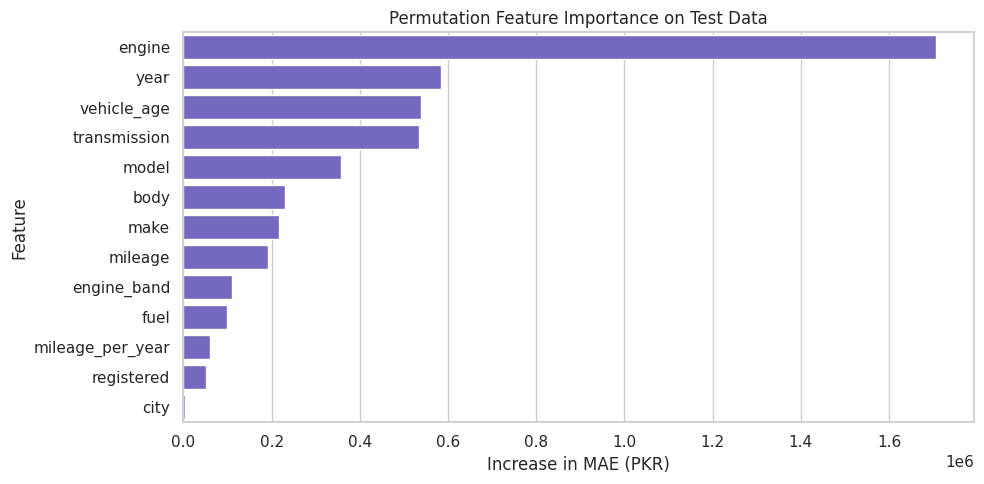

In [24]:
from sklearn.inspection import permutation_importance

importance_size = min(2000, len(X_test))
importance_X = X_test.sample(n=importance_size, random_state=42)
importance_y = y_test.loc[importance_X.index]

importance = permutation_importance(
    final_pipeline,
    importance_X,
    importance_y,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1,
)

feature_importance = pd.DataFrame({
    "Feature": selected_features,
    "Increase in MAE (PKR)": importance.importances_mean,
}).sort_values("Increase in MAE (PKR)", ascending=False)

display(feature_importance)

plt.figure(figsize=(10, 5))
sns.barplot(data=feature_importance, x="Increase in MAE (PKR)", y="Feature", color="slateblue")
plt.title("Permutation Feature Importance on Test Data")
plt.tight_layout()
plt.show()

In [25]:
model_path = "used_car_price_pipeline.joblib"
dump(final_pipeline, model_path)

example_listings = X_test.head(5)
example_predictions = pd.DataFrame({
    "Actual Price (PKR)": y_test.head(5).to_numpy(),
    "Predicted Price (PKR)": np.maximum(final_pipeline.predict(example_listings), 0),
})

display(example_predictions.round(0))

,Actual Price (PKR),Predicted Price (PKR)
0,2870000.0,2643736.0
1,2850000.0,2740040.0
2,2675000.0,2862969.0
3,3850000.0,3541702.0
4,2500000.0,2461826.0


## 11. Key Findings

- Random Forest Regressor was selected as the final model because it achieved the lowest validation MAE among the evaluated models.
- The final model achieved an MAE of approximately PKR 377,481, RMSE of PKR 1,424,968, and R² of 0.927 on the test dataset.
- Tuned Gradient Boosting achieved slightly better validation RMSE and R² scores, but Random Forest performed better on the primary selection metric, MAE.
- Engine capacity, manufacturing year, vehicle age, and transmission were among the most influential features according to permutation importance.
- The model performed better on lower-priced vehicles. Prediction errors increased for expensive vehicles, particularly those priced above PKR 10 million.
- The actual versus predicted price graph showed that most predictions followed the general price trend, although larger errors were observed for some expensive vehicles.



### Conclusion

Random Forest Regressor demonstrated the best performance in terms of validation MAE among the models tested. The final test results indicate that vehicle specifications can be used to predict advertised used-car prices with reasonable accuracy. However, prediction errors vary across price ranges, and additional information about vehicle condition and current market trends could improve model performance.